# Time-Series Data

There are other ways we might want to consider using cloud computing to accelerate our analysis. In the previous example, we took advantage of computation in the cloud by merging together tens of images without having to download them.

We could just as easily merge together hundreds or thousands of images through a data stack: but rather than worrying about producing a final image *composited through time*, we can instead begin to think about how we can *measure change over long time-series*.

In [1]:
import ee      # The main Earth Engine library
import geemap  # A Python package for interactive mapping with Google Earth Engine
import xee     # Transfer data between Earth Engine and xarray

import geopandas as gpd
import pandas as pd
import rioxarray as rxr
import xarray as xr

import matplotlib.pyplot as plt

from shapely.geometry import shape

In [2]:
# =====================================
# Replace this with your own project id
my_project_name = "ee-trchudley"
# =====================================

ee.Authenticate()
ee.Initialize(project=my_project_name) 

## 

## Our region of interest

Note that this week, we will not be setting a large area to assess an image, but a smaller plot of land. I've set a 500 m radius here, but this could easily be larger - for example, 1000-2000 m. The important that is that this area represents a sample of a single surface type, so the sample surface should be homogenous (e.g. entirely a forest). I have chosen an spot of forest in Northern California near the town of Hoopa - you will see why later.

A great example to show time-series over is NDVI over decidious vegetation, so that is what we will do here. This first cell sets all the parameters we will want to explore in this notebooks - you should be able to produce your own data just by changing this cell.

In [3]:
# Location - editable
latitude = 41.017           # Degrees of latitude
longitude = -123.611          # Degrees of longitude
sample_radius = 1000         # radius of sample area around chosen point, in metres

# NDI - editable
type_of_ndi = 'NDVI'  # type of NDI calculated, for filename purposes
r_high = 'B5'  # relevant band name for r_high
r_low = 'B4'   # relevant band name for r_low

# Set up location geometry
point = ee.Geometry.Point(longitude, latitude)  # Create a point
sample_region = point.buffer(sample_radius)     # Buffer the point by the sample radius to create a circular region

Running the below cell will visualise the sample region. If you would like to ensure you are sampling a consistent surface, you can bring up a quick Landsat layer by clicking 🔧 > 🗺️ and select the SATELLITE Provider. 

In [ ]:
Map = geemap.Map()  # Create an empty Map
Map.addLayer(sample_region, {}, "Search Region")  # Add our AOI
Map.centerObject(sample_region, zoom=12)  # Centre our map on the region of interest
Map

Finally, we will get the complete Landsat record over the sample region. I use Top of Atmosphere (TOA) rather than Surface Reflectance (SR) data here - this is because a `simpleCloudScore` function we use below requires TOA data. As a result, I also request e.g. `B2` rather than `B2_SR` band names above, to fit the TOA band name designations.

I do not filter by date - we will do that later - but I do a couple of things to filter cloudy pixels. The first is to filter by the `CLOUD_COVER` metadata only to images that have less then 70% cloud cover within an image. The second, which is slightly more complex, uses the `.map()` function. This feature  will allow us to apply a processing routine to every individual image within the image collection. The `lambda image:` code tells Python _"as you go through the image collection, we will pretend that every individual image has the variable name `image`. Then, perform the calculation to the right of the colon to every `image`."_ You can think of this as another form of looping through a dataset.

Don't worry about the details of the lambda function. It takes advantage of Earth Engine's built in `simpleCloudScore` function. This assigns a probability to every single pixel that the image is cloud. I use this to mask the images only to pixels that have a <20% chance of being cloud. Later in the notebook, we will be calculating the median NDVI value within the sample region - masking the cloudy pixels ensures we aren't also including the NDVI of cloudy regions within the median value. Clouds are the bane of optical remote sensors!

In [ ]:
# Get Landsat 8 and 9 image collection
landsat_collection = ee.ImageCollection("LANDSAT/LC08/C02/T1_TOA").merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_TOA"))

# Filter to desired region and date bounds
landsat_collection = landsat_collection.filterBounds(sample_region)
landsat_collection = landsat_collection.sort('system:time_start')  # Sort by image date
landsat_collection = landsat_collection.filter(ee.Filter.lt('CLOUD_COVER', 70))

# Filter cloudy pixels within the images
landsat_collection = landsat_collection.map(
    lambda image: image.updateMask(ee.Algorithms.Landsat.simpleCloudScore(image).select(['cloud']).lte(20))
)

landsat_collection

Now that we have our cloud-masked image collection, I will show you three different ways we could extract a time-series of NDVI values within the sample region. They are subtly different but may have different uses to you within your project. If you think you aren't being served by the examples I've shown here, then feel free to ask me what you might want - if it's achievable, I'd be happy to write a new script that could extract the data you desire for your project.

The three time-series we're going to extract are as follows. I'm going to refer to them as follows, although they aren't formal names:

 - **Mean monthly NDI**: Average January-December NDI values across a number of years (e.g. January 2013-25, February 2013-25, `...`, December 2013-25).
 - **Time-series mean monthly NDI**: Average monthly NDI values between two time periods (e.g. January 2013, February 2013, `...`, December 2025).
 - **Time-series mean seasonal NDI**: Average NDI values over a set period, every year (e.g. June-August 2013, June-August 2014, `...`, June-August 2025).


## Mean Monthly NDI

The first of our time-series requires only two input variables to be set: the beginning and end year we wish to collect the mean monthly NDI over. I have set this as a standard between 2014 and 2025. Although Landsat data exists for 2013, it didn't launch until the 11th February. As a result, it will not have consistent data for the whole of 2013, and it is best to collect annual datasets from 2014 onwards.

You might wish to consider breaking up this timespan for your project. For instance, maybe there is a difference between the seasonal NDI variation between 2014-2018 and 2019-2025 following some sort of human interference?

In [6]:
year_begin = 2014
year_end = 2025

Now we'll get to the nuts and bolts of the time-series extraction. First, we create an empty pandas DataFrame with `"month"` and `"NDVI"` columns (we get the `"NDVI"` name from the `type_of_ndi` variable, which we set above. This means that were you run with another type - such as NDWI - the column will be named correctly automatically).

We loop through the numbers `1` through `12` as the month variable, filtering our Landsat collection to only that month. If there's no images that month (not impossible), we return `None`. Else, we perform another `map` function, calculating our NDI using the `normalizedDifference` function to calculate the NDI for every image that month based on the `r_high` and `r_low` we set above. We then use the `.median()` function to produce a single composite image that is constructed as the median value from every image in the month. We use a `reduceRegion()` function to calculate the average value in our sample region in this composite image. Finally, we populate our table with this value, before starting again in the next month.

In [7]:
# Create an empty table with the columns ('month' and 'ndi')
monthly_ndi_record = pd.DataFrame({'month': [], type_of_ndi: [], "stddev": []})

# Filter record to years
filtered_collection = landsat_collection.filter(ee.Filter.calendarRange(year_begin, year_end, 'year'))

# Simple 'loading bar' showing the months
print('Month:  JFMAMJJASOND\n        ', end='')

# Loop through months, calculating the mean NDI within the region of interest
for month in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:  # for every month in the range 1 through 12...
    print('.', end='')  # Add a point on the 'loading bar'

    # Filter images only to those within the chosen month
    month_images = filtered_collection.filter(ee.Filter.calendarRange(month, month, 'month'))

    # If there are no available images, return 'NaN' ('not a number'; blank).
    if month_images.size().getInfo() == 0:
        mean_ndi = None
        stddev_ndi = None

    # Else (i.e. if there *are* images...)
    else:
        # Calculate NDI for every image in the image collection (this is called 'mapping')
        month_ndis = month_images.map(lambda image: image.normalizedDifference([r_high, r_low]).rename(type_of_ndi))

        # Calculate a composite NDI image by calculating the median through the image collection
        month_ndi = month_ndis.median()

        # Calculate the average NDI of the composite image within the region of interest
        mean_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.mean(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]
        # Calculate the standard deviation of the NDI values
        stddev_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.stdDev(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]

    # Add a row to the table containing the relevant data
    df = pd.DataFrame({'month': [int(month)], type_of_ndi: [mean_ndi], "stddev": [stddev_ndi]})
    monthly_ndi_record = pd.concat([monthly_ndi_record, df])

# DataFrame wrangling to correct errors introduced by concatenating records.
monthly_ndi_record = monthly_ndi_record.reset_index().drop(columns='index')

# Print 'finished' when we're finished calculating
print('\n        Finished!')

Month:  JFMAMJJASOND
        ............
        Finished!


Now that we have the data in a pandas DataFrame, we can view the data as such:

In [8]:
monthly_ndi_record

,month,NDVI,stddev
0,1.0,0.650770,0.087575
1,2.0,0.655779,0.071157
2,3.0,0.646143,0.054614
3,4.0,0.667669,0.040366
4,5.0,0.689526,0.037699
5,6.0,0.700675,0.034731
6,7.0,0.702229,0.037055
7,8.0,0.632093,0.079333
8,9.0,0.662610,0.051256
9,10.0,0.671316,0.052403


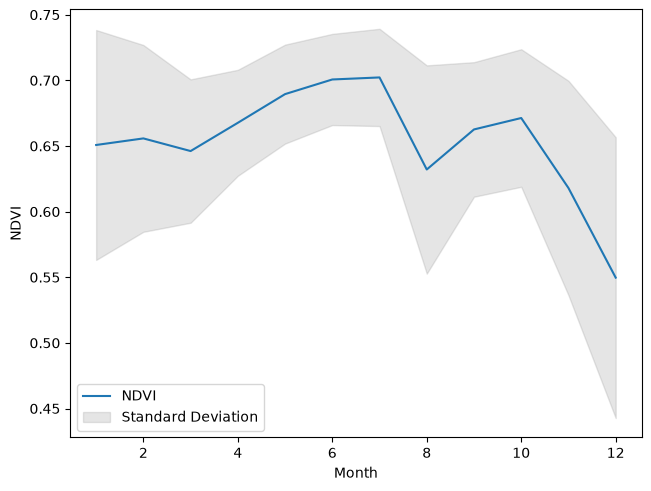

In [9]:
# create an empty figure
fig, ax = plt.subplots(layout='constrained')

# plot the NDI record from the pandas DataFrame
monthly_ndi_record.plot('month', type_of_ndi, ax=ax)

# Plot the standard deviation as a shaded area around the mean
ax.fill_between(monthly_ndi_record['month'],
                monthly_ndi_record[type_of_ndi] - monthly_ndi_record['stddev'],
                monthly_ndi_record[type_of_ndi] + monthly_ndi_record['stddev'],
                color='gray', alpha=0.2, label='Standard Deviation')

# Set the x and y labels
ax.set_xlabel('Month')
ax.set_ylabel(type_of_ndi)

ax.legend()

plt.show()

This NDVI variation makes sense for a deciduous forest: lower in the winter, and higher in the summer.

# Time-series mean monthly NDI

In the section above, we calculate average NDI values for every month based on all years. However, we can also go month-by-month, producing a time-series of NDI behaviour.

This is slightly more time-consuming, so for now we will choose a slightly smaller range of years - 2020 through 2023. You could go all out and set 2013 to present if you like, or just set both years the same (e.g. 2020 and 2020) if you'd only like a single year.

In [10]:
year_begin = 2020
year_end = 2023

The cell below is largely similar to the section above, but notice this time we have two loops: `for year in [years]` and `for month in [months]`. This means we go through ever year in our temporal range, then every month in every one of those years...

In [11]:
# Create an empty table with the relevant columns ('date' and 'ndi')
timeseries_ndi_record = pd.DataFrame({'date': [], type_of_ndi: [], "stddev": []})

# Simple 'loading bar'
print('Year    JFMAMJJASOND')

# Loop through years and months, calculating the mean NDI within the region of interest

for year in list(range(year_begin, year_end+1)): # For every year in the range year_begin to year_end...
    print(f'{year}    ', end='')  # Another 'loading bar' component

    for month in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:  # For every month in the range 1 to 12...
        print('.', end='')  # Another 'loading bar' component

        # Filter images only to those within the chosen month
        month_start = f'{year}-{month}-01'
        month_end = f'{year}-{month+1}-01' if month != 12 else f'{year+1}-01-01'
        month_images = landsat_collection.filterDate(month_start, month_end)

        # If there are no available images, return 'NaN' ('not a number'; blank).
        if month_images.size().getInfo() == 0:
            mean_ndi = None
            stddev_ndi = None

        # Else (i.e. if there *are* images...)
        else:
            # Calculate NDI for every image in the image collection (this is called 'mapping')
            month_ndis = month_images.map(lambda image: image.normalizedDifference([r_high, r_low]).rename(type_of_ndi))

            # Calculate a composite NDI image by calculating the median through the image collection
            month_ndi = month_ndis.median()

            # Calculate the average NDI of the composite image within the region of interest
            mean_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.mean(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]
            # Calculate the standard deviation of the NDI values
            stddev_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.stdDev(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]

        df = pd.DataFrame({'date': [pd.to_datetime(f'{year}-{month}-15')], type_of_ndi: [mean_ndi], "stddev": [stddev_ndi]})
        timeseries_ndi_record = pd.concat([timeseries_ndi_record, df])
    print('')

print('Finished!')

Year    JFMAMJJASOND
2020    ............
2021    ............
2022    ............
2023    ............
Finished!


See what this looks like as a DataFrame:

In [12]:
timeseries_ndi_record.head(10)

,date,NDVI,stddev
0,2020-01-15,NaN,NaN
0,2020-02-15,0.723991,0.067853
0,2020-03-15,0.627695,0.076825
0,2020-04-15,0.714547,0.047347
0,2020-05-15,0.533118,0.083472
0,2020-06-15,0.742575,0.029011
0,2020-07-15,0.733430,0.029693
0,2020-08-15,0.671196,0.064122
0,2020-09-15,0.721125,0.050447
0,2020-10-15,0.683320,0.067009


Note that, as we assign a nominal date to the images, they are set to be the 15th of every month. Just remember that this actually represents a monthly average.

We can also plot this:

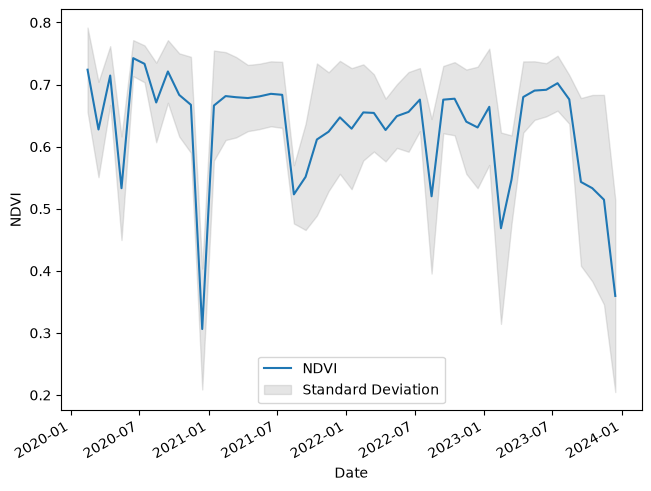

In [13]:
# create an empty figure
fig, ax = plt.subplots(layout='constrained')

# plot the NDI record from the pandas DataFrame
timeseries_ndi_record.plot('date', type_of_ndi, ax=ax)

# Plot the standard deviation as a shaded area around the mean
ax.fill_between(timeseries_ndi_record['date'],
                timeseries_ndi_record[type_of_ndi] - timeseries_ndi_record['stddev'],
                timeseries_ndi_record[type_of_ndi] + timeseries_ndi_record['stddev'],
                color='gray', alpha=0.2, label='Standard Deviation')

# Set the x and y labels
ax.set_xlabel('Date')
ax.set_ylabel(type_of_ndi)

ax.legend()

plt.show()

Notice that our dataset isn't quite as pretty as before, which is likely due to low scene coveraging producing noisy data. Theoretically, we can get a Landsat image every two weeks (and more so as we get closer to the poles, as the satellite tracks begin to converge and parallel images begin to overlap). However, cloud is a big problem: if there are only a few scenes in a month, then there is a likelihood that a lot of these scenes are cloud-covered.

It will be up to your to critically assess your data in your project. Is a spike in your data likely real or an anomaly? This is important to explicitly discuss when weighing up the strengths of your conclusions in your project report.

For instance, in the dataset above it is unlikely that the single-month large negative spikes are realistic. However, the large decline from July 2023 is the visible effects of wildfires! In your project, hopefully you are motivated to assess known events such as this. A wildfire project might combine using a script from week 5, to quantify the areal extent of a wildfire, and the time-series to track recovery rates.

## Time-series mean seasonal NDI

For the final method, we are going to extract a single NDI value per year. However, we will extract this value over a number of months. In the cell below, we set our month_begin and month_end value to 8 (August) and 10 (October) respectively. This will allow us to assess NDVI over the post-summer months, which hopefully might reveal wildfire years. However, you could just as easily set the values to 1 and 12 to assess mean NDVI over the entire year, or 10 and 10 to assess only over October (for example).

In [14]:
year_begin = 2014
year_end = 2025

month_begin = 8
month_end = 10

The cell below will look familiar by this point, with some minor changes (try and find them if you like, and think about what they are doing).

In [15]:
# Create an empty table with the relevant columns ('year' and 'ndi')
seasonal_ndi_record = pd.DataFrame({'year': [], type_of_ndi: [], 'stddev': []})

# Simple 'loading bar'
print('Year')

# Loop through years, calculating the mean NDI within the region of interest

for year in list(range(year_begin, year_end+1)): # For every year in the range year_begin to year_end...
    print(f'{year}... ', end='')  # Another 'loading bar' component

    # Filter images only to those within the chosen month and year
    month_images = landsat_collection.filter(ee.Filter.calendarRange(month_begin, month_end, 'month')).filter(ee.Filter.calendarRange(year, year, 'year'))

    # If there are no available images, return 'NaN' ('not a number'; blank).
    if month_images.size().getInfo() == 0:
        mean_ndi = None
        stddev_ndi = None

    # Else (i.e. if there *are* images...)
    else:
        # Calculate NDI for every image in the image collection (this is called 'mapping')
        month_ndis = month_images.map(lambda image: image.normalizedDifference([r_high, r_low]).rename(type_of_ndi))

        # Calculate a composite NDI image by calculating the median through the image collection
        month_ndi = month_ndis.median()

        # Calculate the average NDI of the composite image within the region of interest
        mean_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.mean(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]
        # Calculate the standard deviation of the NDI values
        stddev_ndi = month_ndi.reduceRegion(reducer=ee.Reducer.stdDev(), geometry=sample_region, scale=30).getInfo()[type_of_ndi]

    df = pd.DataFrame({'year': [year], type_of_ndi: [mean_ndi], 'stddev': [stddev_ndi]})
    seasonal_ndi_record = pd.concat([seasonal_ndi_record, df])

print('Finished!')

Year
2014... 2015... 2016... 2017... 2018... 2019... 2020... 2021... 2022... 2023... 2024... 2025... Finished!


This gives us our final record:

In [16]:
seasonal_ndi_record

,year,NDVI,stddev
0,2014.0,0.744003,0.034127
0,2015.0,0.743847,0.042490
0,2016.0,0.750248,0.030231
0,2017.0,0.738171,0.040556
0,2018.0,0.731830,0.038875
0,2019.0,0.743618,0.032021
0,2020.0,0.701076,0.054629
0,2021.0,0.537193,0.057413
0,2022.0,0.668518,0.060867
0,2023.0,0.548965,0.133059


Which we can plot:

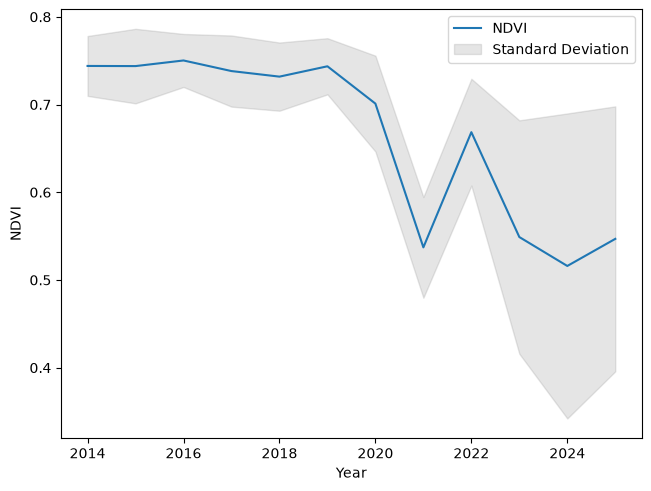

In [17]:


# create an empty figure
fig, ax = plt.subplots(layout='constrained')

# plot the NDI record from the pandas DataFrame
seasonal_ndi_record.plot('year', type_of_ndi, ax=ax)

# Plot the standard deviation as a shaded area around the mean
ax.fill_between(seasonal_ndi_record['year'],
                seasonal_ndi_record[type_of_ndi] - seasonal_ndi_record['stddev'],
                seasonal_ndi_record[type_of_ndi] + seasonal_ndi_record['stddev'],
                color='gray', alpha=0.2, label='Standard Deviation')

# Set the x and y labels
ax.set_xlabel('Year')
ax.set_ylabel(type_of_ndi)

ax.legend()

plt.show()

Looks like there was significant low NDVIs between August-October in 2021 and 2023.  2021 was known in the media for being a significant wildfire year, and we already know that one occurred in 2023. In a project report, we would back up this with published data, including scientific articles and government reports!

:::{note}
Remember to export your Pandas dataframe to a csv file when you are finished with it! You should also make sure you are able to record and plot the location of your sample zone.
:::

## Bonus: Download ERA5 time series using GEE

As a bonus - although GEE is really designed around satellite imagery, it does also store ERA5 data! We can quickly extract measurements at a point in this way.

In [18]:
# Location - editable
latitude = 41.017           # Degrees of latitude
longitude = -123.611        # Degrees of longitude
location_name = 'hoopa'     # recognisable name, to create a useful file name

# Create a point geometry at the specified location
point = ee.Geometry.Point(longitude, latitude)

We will also have to decide what variables we are interested in. For now, I will select only the 2 m air temperature (generally considered the 'surface' air temperature in meteorology), and the total sum precipitation over the month. There are an inordinate amount of options you could add to this list if you would like (e.g. for doing an NDSI project, it might be useful to have snowfall...). A complete catalogue of variables, including useful descriptions of what the data actually represents (units, meanings, etc) can be found on [the Earth Engine documentation](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_MONTHLY_AGGR#bands).

In [19]:
# Names of the variables we want to download -- add more if you like!
variables = [
    'temperature_2m',
    'total_precipitation_sum',
    ]

Now that we have our variables, we can search through the dataset in a way that might look vaguely familiar. We are once again selecting an image collection (this time, the ERA5 option), and filtering to chosen dates and variables. Note that, even though this is a modelling product, Earth Engine still stores and thinks of the dataset as an image (hence, the documentation above referring to 'bands' rather than 'variables'). This is quite a handy way to take advantage of Earth Engine, which is nominally for remote sensing data and image analysis, for modelling purposes! To make things easy, I haven't given you an option for dates - I've set (or 'hard-coded') it to return a dataset from 2013 - 2025, seeing as that is our period of interest over the Landsat 8 record.

Finally, a function 'maps' through the dataset, using a `reduceRegion` function to find the variable values at the pixel that overlaps our study point. It sets these values (along with the year and date) as properties of the image in the image collection - for example, as well as a metadata number for 'cloud cover', it will now have one for temperature at our point.

In [20]:
# Define the dataset as the ERA5 monthly mean data
dataset = ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')

# Filter the dataset to the desired time range
dataset = dataset.filter(ee.Filter.date('2013-01-01', '2025-12-31'))

# Select only the relevant variables
dataset = dataset.select(variables)

# Go through the collection, finding the nearest values to the set lat/lon
dataset = dataset.map(
    lambda image: image.set(
        'era5',
        image.reduceRegion(
            reducer=ee.Reducer.first(),
            geometry=point,
            scale=image.projection().nominalScale()  # Use native resolution
        ).set('year', image.date().get('year')).set('month', image.date().get('month'))
    )
)

We can now extract this data and turn it into a `Pandas` dataframe/table. Don't worry too much about what is going on in this cell - just note that once you run it, it produces a nice and sensible table with all of our data!

In [21]:
# Get this data as a dictionary, and turn it into a Pandas dataframe (table)
era5_dict = dataset.aggregate_array('era5').getInfo()
era5 = pd.DataFrame(era5_dict)

# Construct a proper 'date' column from the year and month data.
dates = pd.to_datetime(dict(year=era5.year, month=era5.month, day=15))

# Drop the 'year' and 'month' columns and insert the 'date' column instead as the first column.
era5.drop(labels=['year', 'month'], axis=1,inplace = True)
era5.insert(0, 'date', dates)

# Visualise table
era5


,date,temperature_2m,total_precipitation_sum
0,2013-01-15,275.081266,0.063698
1,2013-02-15,276.984352,0.046044
2,2013-03-15,280.038248,0.097474
3,2013-04-15,282.888077,0.076010
4,2013-05-15,285.392207,0.059174
...,...,...,...
151,2025-08-15,293.953569,0.002010
152,2025-09-15,291.476218,0.053938
153,2025-10-15,284.058403,0.120501
154,2025-11-15,282.071961,0.168169


We're going to do some things to make things human-readable. First, we'll convert the temperature from Kelvin to Celcius by subtracting 273.15 degrees. Second, we will convert the total monthly rainfall from metres to mm by multiplying by 1000.

If you've included any additional variables, this is the point where you might want to introduce some corrections of your own, after consulting with the documentation.

In [22]:
# Create new 'corrected' table as a copy of the first.
era5_corr = era5.copy()

# Transition temperature from Kelvin to Celcius
era5_corr['temperature_2m'] = era5_corr['temperature_2m'] - 273.15

# Transition total rainfall from m to mm
era5_corr['total_precipitation_sum'] = era5_corr['total_precipitation_sum'] * 1000

# Visualise new table
era5_corr

,date,temperature_2m,total_precipitation_sum
0,2013-01-15,1.931266,63.698174
1,2013-02-15,3.834352,46.044247
2,2013-03-15,6.888248,97.474128
3,2013-04-15,9.738077,76.010174
4,2013-05-15,12.242207,59.174133
...,...,...,...
151,2025-08-15,20.803569,2.010220
152,2025-09-15,18.326218,53.938356
153,2025-10-15,10.908403,120.500714
154,2025-11-15,8.921961,168.168818


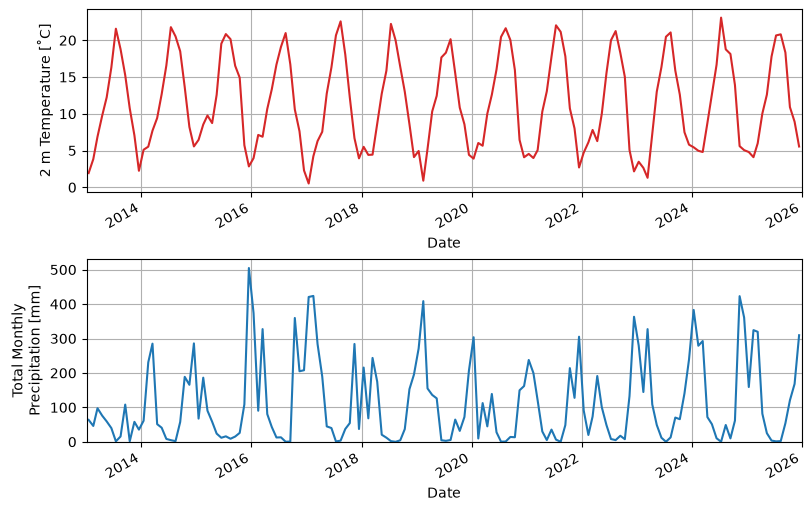

In [23]:
fig, axes = plt.subplots(nrows=2, layout='constrained', figsize=(8, 5))

# For the first axis...
ax = axes[0]
# Plot the temperature in red on the first axis
era5_corr.plot('date', 'temperature_2m', ax=ax, color='tab:red', legend=False)
# Set the y axis label
ax.set_ylabel('2 m Temperature [˚C]')

# For the second axis...
ax = axes[1]
# Plot the total monthly precipitaiton in blue on the second axis
era5_corr.plot('date', 'total_precipitation_sum', ax=ax, color='tab:blue', legend=False)
# Set the y axis label ('\n' forces a line break to fit it on the axis)
ax.set_ylabel('Total Monthly\nPrecipitation [mm]')
# Set the y lower limit to zero
ax.set_ylim(0, None)

for ax in axes:  # Loop through both axes, applying the same rules to both

  # Apply a grid
  ax.grid()

  # Set the x axis limits between 2013 and 2025
  ax.set_xlim(pd.to_datetime('2013-01-01'), pd.to_datetime('2026-01-01'))

  # Set the x axis label to 'Date'
  ax.set_xlabel('Date')

Regardless of what software you choose to plot the data, it's clear we've got a good dataset to analyse and find potential explanations for the trends and events we've observed in our remote sensing data!

In the NDVI data, we saw potential high wildfire years in 2020 and 2023. It's interesting to compare this to our data here. Neither of those years seem to have particularly high mean monthly temperatures through the summer. However, there is quite low precipitation in the 2020-2023 period. A look at the literature may reveal studies that investigate which are stronger controls - and perhaps the solution might lie in other variables. For instance, the Google Earth Engine documentation shows there is a `temperature_2m_max` variable. Maximum temperature might be more important control than mean temperature for initiating wildfires...

## Summary

We have thought about another way we could interrogate cloud-based data, by creating longer timeseries that present data averaged over the span of months. This might be very useful in order to track long-term changes at your study area to track, for instance, the recovery of vegetation from a disturbance event.